# 28 — Training-data readiness and physical-baseline retrieval

Prepare the first **Earth–Moon terrain morphology** experiment for rover traversal exercises. No CNN is trained here. Terrain similarity does not establish mobility, mission suitability or legal access.

This is a development experiment using the five Earth and seven lunar regions already explored. Atacama and Leibnitz Beta Plateau form the first **EDA-exposed development holdout**; the other regions form the training side. Proposed validation/final reserves are never opened. These roles were selected before this baseline run, not from its scores.

The configuration is [terrain_dataset.json](terrain_dataset.json); reusable code is in [terrain_dataset.py](terrain_dataset.py) and [terrain_learning.py](terrain_learning.py). Current scientific decisions remain in [outline.md](../../../outline.md).

## Input contract and decisions to revisit

- Start at **960 m / 30 m = 32 × 32 cells**, with patch-relative elevation (m), slope (degrees), and local elevation SD (m). Local SD is a relief/roughness proxy, not detrended surface roughness.
- Read the accepted processed runs and verify consumed raster hashes. Keep the existing five-channel completeness and natural-land-cover masks, even though the CNN experiment uses three channels. Inventory all excluded lattice windows, including zero-patch region/view combinations.
- Preserve full-context and image-supported lunar views as **separate experiments**. Full-context values may be prior-dominated; a 30 m grid is not proof of 30 m effective resolution. The initial terrain inventory retains strict-view Faustini patches; the earlier zero count concerned stricter environmental completeness, not absent terrain.
- Use notebook 16's center origin 16 / stride 32 cells. Partial edge windows are omitted. Initial tensors contain complete eligible patches only: no gap filling or invented flat terrain. Validity is exported explicitly.
- Keep every region, view, source version and future augmentation in one fold role. Check entire source bounds expanded by at least 150 m on all sides; reject cross-role context overlap. This conservative geometry check does not establish statistical independence.
- Fit channel scaling **only on training patches**, giving each region equal mass. Save a separate scaler and sampling weights for each lunar view; holdout weights are zero. Small regions can be heavily repeated by balanced sampling, so compare with count-weighted training later.
- Keep 300/600 m as follow-up experiments; the initial scale and CNN design are provisional. Do not choose a scale from final-test results.

In [8]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "outline.md").exists())
sys.path.insert(0, str(ROOT))
from notebooks.modeling.terrain_similarity.terrain_dataset import build_dataset
from notebooks.modeling.terrain_similarity.terrain_learning import normalize_tensors

CONFIG = ROOT / "notebooks/modeling/terrain_similarity/terrain_dataset.json"
display(json.loads(CONFIG.read_text(encoding="utf-8")))

{'schema_version': 1,
 'objective': 'Development-only terrain morphology retrieval for rover traversal exercises; no mobility or suitability labels',
 'patch_size_m': 960,
 'spacing_m': 30,
 'context_m': 150,
 'top_k': 5,
 'runs': {'original': 'data/processed/earth_terrain_landcover/20261028T063142045472Z_9d6d3b',
  'death_valley': 'data/processed/earth_terrain_expansion/20261029T075850772998Z_b58cb9',
  'wadi_rum': 'data/processed/earth_terrain_expansion/20261029T084504362605Z_6b826e',
  'moon': 'data/processed/lunar_terrain_views/20261028T084443441751Z_1a794f'},
 'regions': [{'body': 'earth',
   'region': 'atacama_san_pedro',
   'role': 'development',
   'fold': 'holdout',
   'run': 'original'},
  {'body': 'earth',
   'region': 'lanzarote',
   'role': 'development',
   'fold': 'train',
   'run': 'original'},
  {'body': 'earth',
   'region': 'northern_arizona',
   'role': 'development',
   'fold': 'train',
   'run': 'original'},
  {'body': 'earth',
   'region': 'death_valley',
   'rol

## Build a new local run

Run once from the top. This writes tensors, a patch manifest, split evidence, scalers, sampling weights and baseline rankings to a fresh ignored `data/processed/terrain_learning_readiness/` directory. Existing datasets are read-only. A failed/interrupted run must not be treated as complete.

The equivalent terminal command is `python -m notebooks.modeling.terrain_similarity.terrain_dataset`. No additional ML framework is needed at this stage.

In [9]:
OUT = build_dataset(ROOT, CONFIG)
print("Completed run:", OUT.relative_to(ROOT))

atacama_san_pedro natural_screen 3078 eligible patches
lanzarote natural_screen 32 eligible patches
northern_arizona natural_screen 701 eligible patches
death_valley natural_screen 674 eligible patches
wadi_rum natural_screen 1208 eligible patches
A3CLR22_10_Leibnitz_Beta_Plateau full_context 225 eligible patches
A3CLR22_10_Leibnitz_Beta_Plateau image_supported 68 eligible patches
A3CLR22_11_Malapert_Massif full_context 400 eligible patches
A3CLR22_11_Malapert_Massif image_supported 229 eligible patches
A3CLR22_12_deGerlache_Kocher_Massif full_context 361 eligible patches
A3CLR22_12_deGerlache_Kocher_Massif image_supported 216 eligible patches
A3CLR22_2_Haworth full_context 841 eligible patches
A3CLR22_2_Haworth image_supported 129 eligible patches
A3CLR22_3_Faustini_Rim_A full_context 361 eligible patches
A3CLR22_3_Faustini_Rim_A image_supported 71 eligible patches
A3CLR22_4_deGerlache_Rim_2 full_context 361 eligible patches
A3CLR22_4_deGerlache_Rim_2 image_supported 134 eligible patc

## Inspect retention and tensor integrity

`incomplete_terrain` and `policy_rejected` can overlap; do not add them as independent exclusion counts. A zero strict-view count is a selection effect, not evidence that the full-context source has missing heights. The patch manifest preserves source runs, roles, footprint coordinates, CRS, physical scale and tensor positions.

In [10]:
inventory = pd.read_csv(OUT / "inventory.csv")
patches = pd.read_csv(OUT / "patches.csv")
display(inventory)

for view in ["full_context", "image_supported"]:
    scaler = json.loads((OUT / f"scaler_{view}.json").read_text())
    sample = patches.loc[patches["view"] == view].iloc[0]
    with np.load(OUT / sample["shard"], allow_pickle=False) as stored:
        values = stored["physical"][int(sample["tensor_index"]):int(sample["tensor_index"]) + 1]
        normalized, valid = normalize_tensors(values, np.array(scaler["mean"]), np.array(scaler["scale"]))
        assert valid.all() and np.isfinite(normalized).all()
        assert np.array_equal(stored["valid"][int(sample["tensor_index"])], valid[0])
    display({"view": view, "shape": normalized.shape, "training_regions": scaler["training_regions"],
             "mean": scaler["mean"], "scale": scaler["scale"]})

,body,region,view,fold,lattice_windows,incomplete_terrain,policy_rejected,eligible,edge_remainder_cells
0,earth,atacama_san_pedro,natural_screen,holdout,5865,149,2787,3078,122280
1,earth,lanzarote,natural_screen,train,3538,154,3506,32,60988
2,earth,northern_arizona,natural_screen,train,16472,375,15771,701,165520
3,earth,death_valley,natural_screen,train,2622,95,1948,674,98628
4,earth,wadi_rum,natural_screen,train,2162,157,954,1208,26977
5,moon,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,holdout,256,31,31,225,23012
6,moon,A3CLR22_10_Leibnitz_Beta_Plateau,image_supported,holdout,256,188,188,68,23012
7,moon,A3CLR22_11_Malapert_Massif,full_context,train,441,41,41,400,39116
8,moon,A3CLR22_11_Malapert_Massif,image_supported,train,441,212,212,229,39116
9,moon,A3CLR22_12_deGerlache_Kocher_Massif,full_context,train,400,39,39,361,36624


{'view': 'full_context',
 'shape': (1, 3, 32, 32),
 'training_regions': ['wadi_rum',
  'A3CLR22_2_Haworth',
  'northern_arizona',
  'death_valley',
  'A3CLR22_11_Malapert_Massif',
  'A3CLR22_12_deGerlache_Kocher_Massif',
  'A3CLR22_4_deGerlache_Rim_2',
  'A3CLR22_3_Faustini_Rim_A',
  'A3CLR22_5_Connecting_Ridge_Extension',
  'lanzarote'],
 'mean': [2.213121894704088e-09, 9.73280058127616, 16.190194924937575],
 'scale': [57.73091099758054, 7.909030447224082, 13.13386235713865]}

{'view': 'image_supported',
 'shape': (1, 3, 32, 32),
 'training_regions': ['wadi_rum',
  'northern_arizona',
  'death_valley',
  'A3CLR22_11_Malapert_Massif',
  'A3CLR22_12_deGerlache_Kocher_Massif',
  'A3CLR22_5_Connecting_Ridge_Extension',
  'A3CLR22_4_deGerlache_Rim_2',
  'A3CLR22_2_Haworth',
  'A3CLR22_3_Faustini_Rim_A',
  'lanzarote'],
 'mean': [-2.0126066464216803e-09, 12.29682411337384, 20.798103332189402],
 'scale': [71.99080359917296, 8.591653832350891, 14.513639302806027]}

## Physical baseline: three separate transfer cases

Use the existing fixed-band slope/relief discrepancy plus planarity from notebook 17. The worst normalized difference determines rank; ties use patch IDs. Local SD remains a reported descriptor, but is not in this baseline score. Lower scores mean closer selected physical descriptors. **A score of 1 is an exploratory band boundary, not a relevance label or a validated no-match threshold.**

Compare held-out lunar queries against training Earth candidates, training lunar queries against held-out Earth candidates, and both held out. Keep the same candidate pools for a later CNN comparison. Regional summaries and equal-region macro summaries are descriptive; there are no accuracy, recall or relevance claims yet.

In [11]:
rankings = pd.read_csv(OUT / "baseline_top_k.csv")
display(pd.read_csv(OUT / "baseline_by_region.csv"))
display(pd.read_csv(OUT / "baseline_region_macro.csv"))
display(rankings.head(10))

,case,view,region,queries,mean_top_k_regions,median_best_discrepancy
0,both_heldout,full_context,A3CLR22_10_Leibnitz_Beta_Plateau,225,1.000000,0.853919
1,both_heldout,image_supported,A3CLR22_10_Leibnitz_Beta_Plateau,68,1.000000,1.373503
2,heldout_candidates,full_context,A3CLR22_11_Malapert_Massif,400,1.000000,1.174468
3,heldout_candidates,full_context,A3CLR22_12_deGerlache_Kocher_Massif,361,1.000000,0.973901
4,heldout_candidates,full_context,A3CLR22_2_Haworth,841,1.000000,0.612894
5,heldout_candidates,full_context,A3CLR22_3_Faustini_Rim_A,361,1.000000,0.705643
6,heldout_candidates,full_context,A3CLR22_4_deGerlache_Rim_2,361,1.000000,0.761070
7,heldout_candidates,full_context,A3CLR22_5_Connecting_Ridge_Extension,361,1.000000,0.872810
8,heldout_candidates,image_supported,A3CLR22_11_Malapert_Massif,229,1.000000,1.488628
9,heldout_candidates,image_supported,A3CLR22_12_deGerlache_Kocher_Massif,216,1.000000,1.211308


,case,view,mean_top_k_regions,median_best_discrepancy
0,both_heldout,full_context,1.000000,0.853919
1,both_heldout,image_supported,1.000000,1.373503
2,heldout_candidates,full_context,1.000000,0.850131
3,heldout_candidates,image_supported,1.000000,1.302251
4,heldout_queries,full_context,1.386667,2.443363
5,heldout_queries,image_supported,1.088235,4.346731


,case,query_id,query_region,view,candidate_id,candidate_region,rank,band_discrepancy,delta_slope_median_deg,delta_slope_p90_deg,delta_central_relief_m,delta_plane_residual_fraction,delta_local_sd_median_m
0,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,wadi_rum:natural_screen:592:80:960,wadi_rum,1,1.613900,-1.598066,-2.786145,-18.605630,-0.000841,-2.506916
1,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,death_valley:natural_screen:816:944:960,death_valley,2,1.827356,-1.827356,-1.197208,-19.284015,-0.014371,-2.453693
2,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,death_valley:natural_screen:368:1168:960,death_valley,3,2.289243,-0.298150,4.578486,-22.221936,0.150971,-0.863542
3,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,wadi_rum:natural_screen:912:176:960,wadi_rum,4,2.373360,-1.060487,4.743543,-7.088715,0.237336,-1.062435
4,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,wadi_rum:natural_screen:976:112:960,wadi_rum,5,2.452764,-1.947964,-0.085533,-26.371564,0.054744,-3.494083
5,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,wadi_rum:natural_screen:1008:176:960,wadi_rum,1,1.392460,0.084437,0.133011,-19.061118,0.114239,0.377211
6,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,wadi_rum:natural_screen:368:48:960,wadi_rum,2,1.446886,0.306425,2.893773,-13.270013,0.113475,2.887333
7,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,wadi_rum:natural_screen:784:304:960,wadi_rum,3,1.681905,-0.956805,0.471114,-22.452820,0.089163,-1.404296
8,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,wadi_rum:natural_screen:240:48:960,wadi_rum,4,1.700968,-0.522352,3.046045,-11.848352,0.170097,-0.201748
9,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,wadi_rum:natural_screen:1008:80:960,wadi_rum,5,1.730386,0.272516,1.628596,-23.004547,0.011950,0.504433


## Inspect examples in physical units

Each row shows one query and its top three Earth candidates. Elevation is centered within each patch, but the row shares one color scale so height differences remain visible. These examples are selected by sorted query ID, not by attractive matches. No image panels represent environmental suitability.

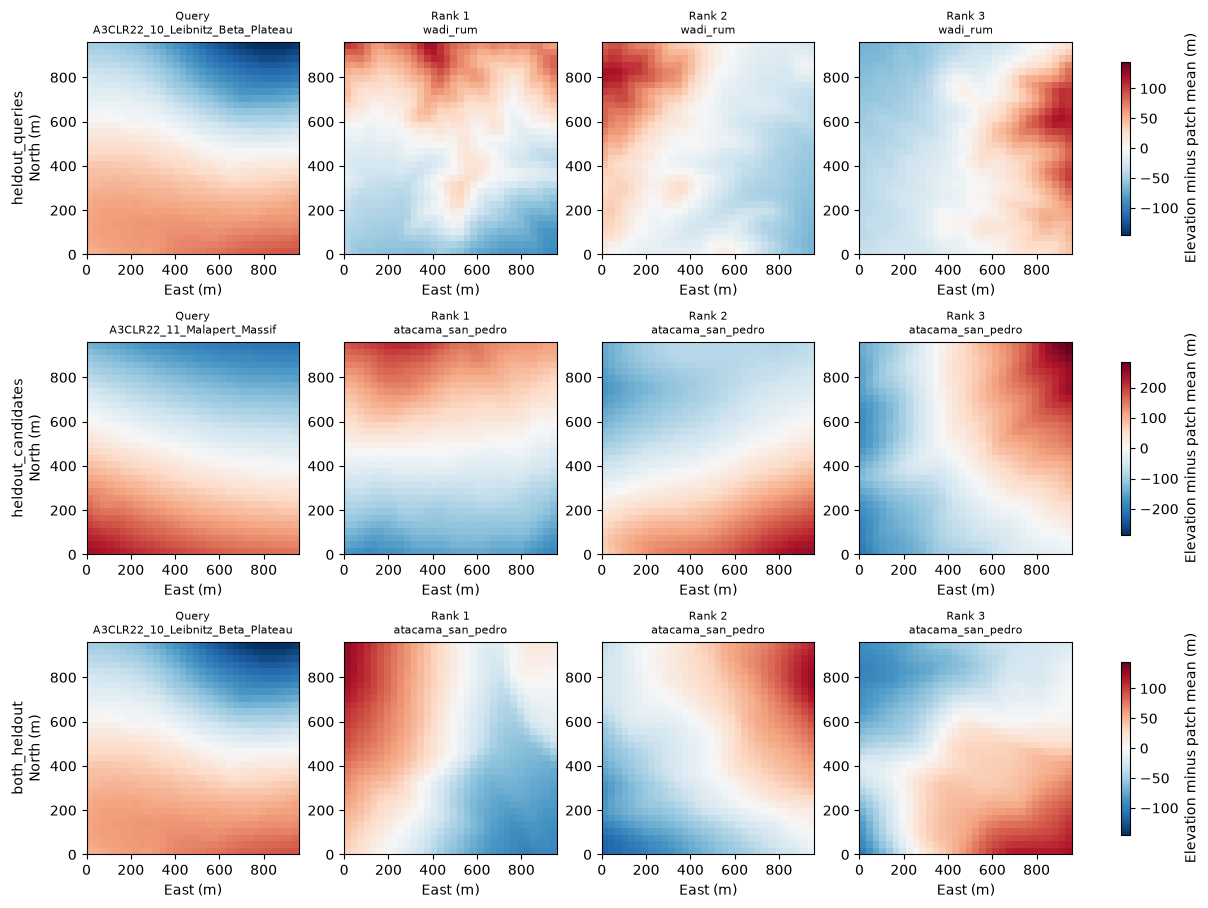

In [12]:
lookup = patches.set_index("patch_id")
fig, axes = plt.subplots(3, 4, figsize=(12, 9), constrained_layout=True)
for row, case in enumerate(["heldout_queries", "heldout_candidates", "both_heldout"]):
    part = rankings.loc[(rankings["case"] == case) & (rankings["view"] == "full_context")]
    query_id = min(part["query_id"].unique())
    chosen = part.loc[part["query_id"] == query_id].sort_values("rank").head(3)
    ids = [query_id, *chosen["candidate_id"].tolist()]
    terrain_images = []
    for patch_id in ids:
        record = lookup.loc[patch_id]
        with np.load(OUT / record["shard"], allow_pickle=False) as stored:
            terrain_images.append(stored["physical"][int(record["tensor_index"]), 0])
    limit = max(float(np.max(np.abs(values))) for values in terrain_images) or 1.
    for column, (patch_id, values) in enumerate(zip(ids, terrain_images, strict=True)):
        record = lookup.loc[patch_id]
        extent_m = float(record["size_m"])
        im = axes[row, column].imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit,
                                      extent=(0, extent_m, 0, extent_m))
        axes[row, column].set_title(("Query" if column == 0 else f"Rank {column}") + "\n" + record["region"], fontsize=8)
        axes[row, column].set_xlabel("East (m)")
    axes[row, 0].set_ylabel(case + "\nNorth (m)")
    fig.colorbar(im, ax=list(axes[row]), label="Elevation minus patch mean (m)", shrink=.7)
plt.show()
plt.close(fig)

## Independent relevance review and the next experiment

`review_pairs_unlabeled.csv` is a starting review worksheet: two seeded queries per nonempty lunar region/view, up to three top baseline candidates plus two random candidates per applicable transfer case, shuffled without scores. These choices do **not** manufacture positive or negative labels. Reviewers must be able to mark every candidate irrelevant or uncertain.

Before evaluating a CNN, agree on a morphology rubric: ridge/valley arrangement, steep-transition placement, relief at this physical scale, and whether differences matter for the specified exercise. Record `relevance` as relevant / partly relevant / irrelevant / uncertain, with reviewer and reason. Review physical maps and source limitations independently of rank. This baseline-derived pool is not an unbiased retrieval benchmark; add pooled CNN candidates and additional independent/random candidates before comparison.

Next, notebook 29 can test a small self-supervised CNN against this baseline. Check source/body/mask shortcuts, preserve terrain amplitudes, keep augmentations within roles, and compare region-balanced versus count-weighted sampling. Define relevance metrics and no-match rules before judging models. Training loss alone is not proof of analog relevance. Further EDA should address failures found here; no final reserves are needed for this development step.

In [13]:
review = pd.read_csv(OUT / "review_pairs_unlabeled.csv", keep_default_na=False)
display(review.head(10))
print(len(review), "unlabeled review pairs; no model trained")
print("Run provenance:", OUT / "provenance.json")

,case,query_id,candidate_id,relevance,reviewer,reason
0,both_heldout,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,atacama_san_pedro:natural_screen:240:1328:960,,,
1,both_heldout,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,atacama_san_pedro:natural_screen:976:368:960,,,
2,both_heldout,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,atacama_san_pedro:natural_screen:784:176:960,,,
3,both_heldout,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,atacama_san_pedro:natural_screen:688:1232:960,,,
4,both_heldout,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,atacama_san_pedro:natural_screen:1008:1200:960,,,
5,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,wadi_rum:natural_screen:880:208:960,,,
6,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,northern_arizona:natural_screen:2000:4496:960,,,
7,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,death_valley:natural_screen:528:1424:960,,,
8,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,wadi_rum:natural_screen:592:816:960,,,
9,heldout_queries,A3CLR22_10_Leibnitz_Beta_Plateau:full_context:...,wadi_rum:natural_screen:1040:48:960,,,


160 unlabeled review pairs; no model trained
Run provenance: .\data\processed\terrain_learning_readiness\20261102T143626105895Z_250cb0\provenance.json
